# LAB3 - Bài 1 (Trang 1): Phân lớp Iris bằng Decision Tree, Naïve Bayes, KNN, Neural Network
**Đinh Nhật Huyền Nhân - 6451071055 - CQ.64.CNTT**

In [1]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# a) Đọc bộ dữ liệu Iris từ sklearn
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

iris = load_iris()
print("Đã đọc bộ dữ liệu Iris:", type(iris))
print("Các khóa:", list(iris.keys()))

Đinh Nhật Huyền Nhân - 6451071055


Đã đọc bộ dữ liệu Iris: <class 'sklearn.utils._bunch.Bunch'>
Các khóa: ['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module']


In [2]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# b) Khảo sát bộ dữ liệu Iris
print("Tên các thuộc tính:", iris.feature_names)
print("Thuộc tính phân lớp (tên các lớp):", iris.target_names.tolist())
print("data.shape   =", iris.data.shape)
print("target.shape =", iris.target.shape)
print("Số lượng mẫu:", iris.data.shape[0], "| Số lượng thuộc tính:", iris.data.shape[1])
print("\n5 mẫu dữ liệu đầu tiên:")
for i in range(5):
    print(i, iris.data[i], "-> nhãn", iris.target[i], f"({iris.target_names[iris.target[i]]})")

df = pd.DataFrame(iris.data, columns=iris.feature_names)
print("\nThống kê mô tả:")
pd.set_option("display.width", 120)
print(df.describe())

Đinh Nhật Huyền Nhân - 6451071055
Tên các thuộc tính: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Thuộc tính phân lớp (tên các lớp): ['setosa', 'versicolor', 'virginica']
data.shape   = (150, 4)
target.shape = (150,)
Số lượng mẫu: 150 | Số lượng thuộc tính: 4

5 mẫu dữ liệu đầu tiên:
0 [5.1 3.5 1.4 0.2] -> nhãn 0 (setosa)
1 [4.9 3.  1.4 0.2] -> nhãn 0 (setosa)
2 [4.7 3.2 1.3 0.2] -> nhãn 0 (setosa)
3 [4.6 3.1 1.5 0.2] -> nhãn 0 (setosa)
4 [5.  3.6 1.4 0.2] -> nhãn 0 (setosa)

Thống kê mô tả:
       sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
count         150.000000        150.000000         150.000000        150.000000
mean            5.843333          3.057333           3.758000          1.199333
std             0.828066          0.435866           1.765298          0.762238
min             4.300000          2.000000           1.000000          0.100000
25%             5.100000          2.800000           1.600000   

In [3]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# c) Chuẩn hóa dữ liệu về đoạn [0,1]: chia mỗi giá trị cho giá trị lớn nhất của cột
X = iris.data
Y = iris.target
X_max = X.max(axis=0)
print("Giá trị lớn nhất mỗi cột:", X_max)
X = X / X_max
print("5 mẫu sau chuẩn hóa:\n", np.round(X[:5], 4))
print("Min sau chuẩn hóa:", X.min(axis=0))
print("Max sau chuẩn hóa:", X.max(axis=0))

Đinh Nhật Huyền Nhân - 6451071055
Giá trị lớn nhất mỗi cột: [7.9 4.4 6.9 2.5]
5 mẫu sau chuẩn hóa:
 [[0.6456 0.7955 0.2029 0.08  ]
 [0.6203 0.6818 0.2029 0.08  ]
 [0.5949 0.7273 0.1884 0.08  ]
 [0.5823 0.7045 0.2174 0.08  ]
 [0.6329 0.8182 0.2029 0.08  ]]
Min sau chuẩn hóa: [0.5443038  0.45454545 0.14492754 0.04      ]
Max sau chuẩn hóa: [1. 1. 1. 1.]


In [4]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# d) Chia train/test theo tỷ lệ 8:2
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)

Đinh Nhật Huyền Nhân - 6451071055
X_train: (120, 4) | y_train: (120,)
X_test : (30, 4) | y_test : (30,)


Đinh Nhật Huyền Nhân - 6451071055


===== Decision Tree =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000         9
   virginica     1.0000    1.0000    1.0000        11

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



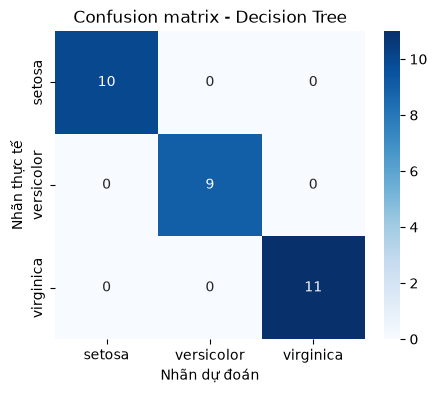

In [5]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# e) Phân lớp bằng Cây quyết định (Decision Tree)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def danh_gia(ten_mo_hinh, y_true, y_pred, labels=iris.target_names):
    print(f"===== {ten_mo_hinh} =====")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print(classification_report(y_true, y_pred, target_names=labels, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.xlabel("Nhãn dự đoán"); plt.ylabel("Nhãn thực tế")
    plt.title(f"Confusion matrix - {ten_mo_hinh}")
    plt.show()

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)                 # Huấn luyện trên tập train
y_pred_dt = dt.predict(X_test)           # Dự đoán nhãn cho tập test
danh_gia("Decision Tree", y_test, y_pred_dt)

Đinh Nhật Huyền Nhân - 6451071055
===== Naive Bayes =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000         9
   virginica     1.0000    1.0000    1.0000        11

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



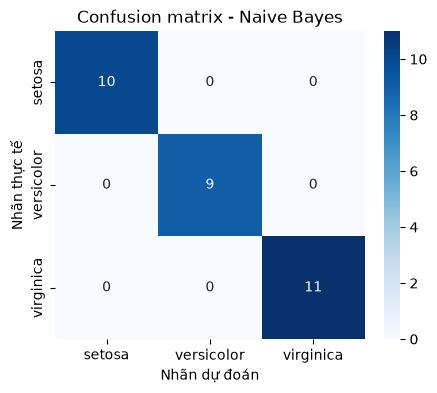

In [6]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# f) Phân lớp bằng Naïve Bayes (GaussianNB)
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)
danh_gia("Naive Bayes", y_test, y_pred_nb)

Đinh Nhật Huyền Nhân - 6451071055
===== KNN (k=5) =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000         9
   virginica     1.0000    1.0000    1.0000        11

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



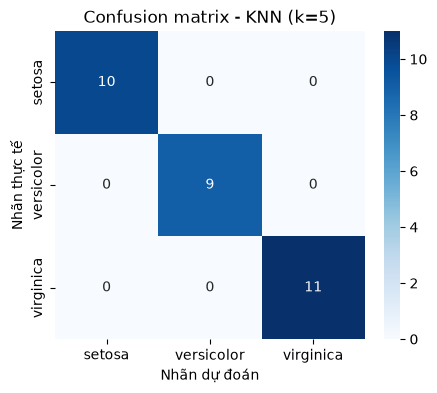

In [7]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# g) Phân lớp bằng K Nearest Neighbors
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
danh_gia("KNN (k=5)", y_test, y_pred_knn)

In [8]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# h) Xây dựng Neural Network: 2 hidden layers (10, 20 neuron - ReLU) + output layer Softmax
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
tf.keras.utils.set_random_seed(42)

so_lop = len(np.unique(Y))
nn = Sequential([
    Input(shape=(X_train.shape[1],)),          # input_shape = 4 thuộc tính
    Dense(10, activation="relu"),              # hidden layer 1: 10 neuron, fully connected
    Dense(20, activation="relu"),              # hidden layer 2: 20 neuron, fully connected
    Dense(so_lop, activation="softmax"),       # output layer: số neuron = số class
])
nn.summary()

Đinh Nhật Huyền Nhân - 6451071055


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            63 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333 (1.30 KB)

 Trainable params: 333 (1.30 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# h) Biên dịch mô hình
nn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("Đã biên dịch: optimizer=adam, loss=sparse_categorical_crossentropy, metrics=accuracy")

Đinh Nhật Huyền Nhân - 6451071055
Đã biên dịch: optimizer=adam, loss=sparse_categorical_crossentropy, metrics=accuracy


In [10]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# h) Huấn luyện: epochs=100, batch_size=1, verbose=1
history_nn = nn.fit(X_train, y_train, epochs=100, batch_size=1, verbose=1)

Đinh Nhật Huyền Nhân - 6451071055
Epoch 1/100


  1/120 ━━━━━━━━━━━━━━━━━━━━ 57s 482ms/step - accuracy: 1.0000 - loss: 0.8995

 67/120 ━━━━━━━━━━━━━━━━━━━━ 0s 763us/step - accuracy: 0.2836 - loss: 1.0651 

120/120 ━━━━━━━━━━━━━━━━━━━━ 1s 835us/step - accuracy: 0.3917 - loss: 1.0245


Epoch 2/100


  1/120 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 1.0000 - loss: 0.8175

... (390 outputs left out)

Epoch 100/100


  1/120 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 1.0000 - loss: 0.0012

 68/120 ━━━━━━━━━━━━━━━━━━━━ 0s 754us/step - accuracy: 0.9853 - loss: 0.0404

120/120 ━━━━━━━━━━━━━━━━━━━━ 0s 836us/step - accuracy: 0.9750 - loss: 0.0741


Đinh Nhật Huyền Nhân - 6451071055


===== Neural Network =====
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000         9
   virginica     1.0000    1.0000    1.0000        11

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30



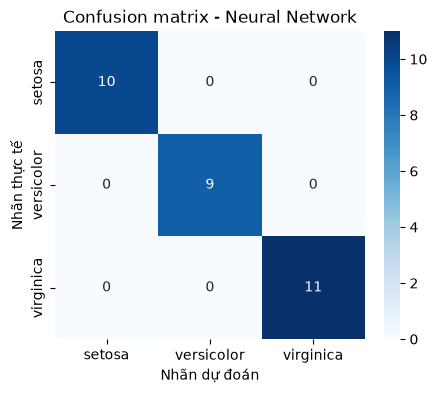

In [11]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# h) Dự đoán, đánh giá trên tập test
y_prob_nn = nn.predict(X_test, verbose=0)    # xác suất cho mỗi mẫu, mỗi class
y_pred_nn = np.argmax(y_prob_nn, axis=1)     # chọn class có xác suất lớn nhất
danh_gia("Neural Network", y_test, y_pred_nn)

In [12]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# i) Dự đoán 03 mẫu dữ liệu mới bằng các mô hình đã huấn luyện
mau_moi = np.array([[6.2, 2.9, 4.3, 1.3],
                    [5.1, 3.5, 1.4, 0.2],
                    [7.3, 2.8, 6.4, 2.1]])
mau_moi_cc = mau_moi / X_max     # chuẩn hóa giống dữ liệu huấn luyện
ket_qua = pd.DataFrame({
    "Mẫu": [str(m) for m in mau_moi.tolist()],
    "Decision Tree": iris.target_names[dt.predict(mau_moi_cc)],
    "Naive Bayes": iris.target_names[nb.predict(mau_moi_cc)],
    "KNN": iris.target_names[knn.predict(mau_moi_cc)],
    "Neural Network": iris.target_names[np.argmax(nn.predict(mau_moi_cc, verbose=0), axis=1)],
})
print(ket_qua.to_string(index=False))

Đinh Nhật Huyền Nhân - 6451071055
                 Mẫu Decision Tree Naive Bayes        KNN Neural Network
[6.2, 2.9, 4.3, 1.3]    versicolor  versicolor versicolor     versicolor
[5.1, 3.5, 1.4, 0.2]        setosa      setosa     setosa         setosa
[7.3, 2.8, 6.4, 2.1]     virginica   virginica  virginica      virginica


In [13]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# j) So sánh hiệu suất các mô hình trên tập test
from sklearn.metrics import precision_recall_fscore_support
bang = []
for ten, yp in [("Decision Tree", y_pred_dt), ("Naive Bayes", y_pred_nb),
                ("KNN", y_pred_knn), ("Neural Network", y_pred_nn)]:
    p, r, f, _ = precision_recall_fscore_support(y_test, yp, average="macro", zero_division=0)
    bang.append([ten, accuracy_score(y_test, yp), p, r, f])
bang = pd.DataFrame(bang, columns=["Mô hình", "Accuracy", "Precision(macro)", "Recall(macro)", "F1(macro)"])
print(bang.round(4).to_string(index=False))

Đinh Nhật Huyền Nhân - 6451071055
       Mô hình  Accuracy  Precision(macro)  Recall(macro)  F1(macro)
 Decision Tree       1.0               1.0            1.0        1.0
   Naive Bayes       1.0               1.0            1.0        1.0
           KNN       1.0               1.0            1.0        1.0
Neural Network       1.0               1.0            1.0        1.0


In [14]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# j) Tập test chỉ có 30 mẫu nên kiểm tra thêm bằng 10-fold cross validation trên toàn bộ dữ liệu
from sklearn.model_selection import cross_val_score, StratifiedKFold
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
for ten, mh in [("Decision Tree", DecisionTreeClassifier(random_state=42)),
                ("Naive Bayes", GaussianNB()), ("KNN (k=5)", KNeighborsClassifier(n_neighbors=5))]:
    diem = cross_val_score(mh, X, Y, cv=cv, scoring="accuracy")
    print(f"{ten:14s}: accuracy trung bình 10-fold = {diem.mean():.4f} ± {diem.std():.4f}")

Đinh Nhật Huyền Nhân - 6451071055
Decision Tree : accuracy trung bình 10-fold = 0.9333 ± 0.0516
Naive Bayes   : accuracy trung bình 10-fold = 0.9533 ± 0.0521
KNN (k=5)     : accuracy trung bình 10-fold = 0.9600 ± 0.0533


**j) Nhận xét, đánh giá hiệu suất các mô hình**
- Trên tập test (30 mẫu, random_state=42), cả 4 mô hình Decision Tree, Naïve Bayes, KNN và Neural Network đều đạt Accuracy = Precision = Recall = F1-score = 1.0; ma trận nhầm lẫn chỉ có giá trị trên đường chéo.
- Iris là bộ dữ liệu nhỏ và dễ tách lớp: lớp setosa tách hẳn khỏi hai lớp còn lại; versicolor và virginica chỉ chồng lấn một ít ở petal length/petal width. Vì vậy một tập test 30 mẫu không đủ để phân biệt mô hình nào tốt hơn.
- Khi đánh giá bằng 10-fold cross validation trên toàn bộ dữ liệu: KNN ≈ 0.960, Naïve Bayes ≈ 0.953, Decision Tree ≈ 0.933; Neural Network (Bài 4) ≈ 0.973. Decision Tree thấp nhất vì cây không giới hạn độ sâu dễ bị overfitting, các mô hình còn lại tương đương nhau.
- Neural Network cho kết quả tốt nhưng tốn thời gian huấn luyện hơn nhiều (100 epoch, batch_size=1) và phụ thuộc vào khởi tạo ngẫu nhiên. Với bộ dữ liệu nhỏ như Iris, các mô hình đơn giản như KNN hoặc Naïve Bayes là đủ.
- Với 3 mẫu mới, cả 4 mô hình đều dự đoán giống nhau: [6.2, 2.9, 4.3, 1.3] → versicolor, [5.1, 3.5, 1.4, 0.2] → setosa, [7.3, 2.8, 6.4, 2.1] → virginica.